# Machine Learning vs Deep Learning: Model Comparison for Air Quality Prediction

## Research Objective

The objective of this study is to compare the performance of six Machine Learning (ML) models and four Deep Learning (DL) models for air quality prediction and extreme pollution analysis.

### Machine Learning Models
1. Linear Regression
2. Logistic Regression
3. Naive Bayes
4. Support Vector Machine (SVM)
5. Random Forest
6. XGBoost

### Deep Learning Models
1. Multilayer Perceptron (MLP)
2. Recurrent Neural Network (RNN)
3. Gated Recurrent Unit (GRU)
4. Transformer

### Evaluation Approach

The models will be evaluated using the available experimental results and appropriate evaluation metrics. Regression models will be compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R². Classification models will be evaluated using suitable classification metrics where applicable.

The study will also examine model performance during extreme pollution episodes, defined as US_AQI ≥ 201, wherever the required evaluation results are available.

### Research Scope

This notebook consolidates the existing ML and DL experimental results into a structured comparison, supported by tables, visualizations, performance analysis, and research conclusions.

In [1]:
#  Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
#  Locate Existing ML and DL Notebooks

from pathlib import Path

PROJECT_DIR = Path.cwd()

print("Current project directory:", PROJECT_DIR)
print("\nNotebook files found:")

for file in sorted(PROJECT_DIR.glob("*.ipynb")):
    print("-", file.name)

Current project directory: C:\Users\baris\OneDrive\Desktop\Air_Quality_Research\notebooks

Notebook files found:
- 01_EDA_Air_Quality.ipynb
- 02_Machine_Learning_Air_Quality.ipynb
- 03_Deep_Learning_Air_Quality.ipynb
- 04_ML_vs_DL_Comparison.ipynb


In [4]:
#  Load Existing ML & DL Results

import json
from pathlib import Path

PROJECT_DIR = Path.cwd()

ML_NOTEBOOK = PROJECT_DIR / "02_Machine_Learning_Air_Quality.ipynb"
DL_NOTEBOOK = PROJECT_DIR / "03_Deep_Learning_Air_Quality.ipynb"


def load_saved_results(notebook_path):
    if not notebook_path.exists():
        print(f"NOT FOUND: {notebook_path.name}")
        return None

    with open(notebook_path, "r", encoding="utf-8") as file:
        notebook_data = json.load(file)

    print(f"\nNotebook: {notebook_path.name}")
    print("Notebook found successfully.")

    saved_outputs = []

    for cell_number, cell in enumerate(
        notebook_data.get("cells", []), start=1
    ):
        for output in cell.get("outputs", []):
            output_type = output.get("output_type")

            if output_type == "stream":
                text_output = "".join(output.get("text", []))
                if text_output.strip():
                    saved_outputs.append(
                        (cell_number, text_output[:500])
                    )

            elif output_type == "execute_result":
                data = output.get("data", {})
                text_output = data.get("text/plain", [])
                if text_output:
                    saved_outputs.append(
                        (cell_number, "".join(text_output)[:500])
                    )

    print("Saved text outputs found:", len(saved_outputs))

    for cell_number, text_output in saved_outputs[:5]:
        print(f"\nCell {cell_number}:")
        print(text_output)

    return notebook_data


ml_notebook_data = load_saved_results(ML_NOTEBOOK)
dl_notebook_data = load_saved_results(DL_NOTEBOOK)

print("\n inspection completed.")


Notebook: 02_Machine_Learning_Air_Quality.ipynb
Notebook found successfully.
Saved text outputs found: 36

Cell 1:
All required libraries imported successfully!


Cell 2:
Dataset loaded successfully!
Shape of dataset: (842160, 71)


Cell 3:
Target Variable: US_AQI

US_AQI Data Type: float64
Missing US_AQI Values: 145

US_AQI Statistics:
count    842015.000000
mean         96.804419
std          70.784455
min           9.000000
25%          59.000000
50%          84.000000
75%         128.000000
max        2742.000000
Name: US_AQI, dtype: float64


Cell 4:
Feature selection completed successfully!

Original Dataset Shape: (842160, 71)
Feature Dataset Shape: (842160, 51)
Target Shape: (842160,)

Removed Columns:
- US_AQI
- US_AQI_PM25
- US_AQI_PM10
- US_AQI_NO2
- US_AQI_O3
- US_AQI_CO
- EU_AQI
- EU_AQI_PM25
- EU_AQI_PM10
- AQI_Category
- PM25_Category_India
- Temp_80m_C
- Temp_120m_C
- Temp_180m_C
- Wind_Speed_80m_kmh
- Wind_Speed_120m_kmh
- UV_Index
- NH3_ugm3
- Inversion_Strength_C
- 

In [5]:
#  Verify Results of All 10 Models

expected_models = {
    "Machine Learning": [
        "Linear Regression",
        "Logistic Regression",
        "Naive Bayes",
        "SVM",
        "Random Forest",
        "XGBoost"
    ],
    "Deep Learning": [
        "MLP",
        "RNN",
        "GRU",
        "Transformer"
    ]
}

def inspect_models(notebook_data, model_list):
    if notebook_data is None:
        return

    notebook_text = "\n".join(
        "".join(cell.get("source", []))
        for cell in notebook_data.get("cells", [])
    ).lower()

    for model in model_list:
        search_name = model.lower()
        found = search_name in notebook_text
        print(f"{model}: {'Found in code' if found else 'Not found by name'}")

print("=== MACHINE LEARNING MODELS ===")
inspect_models(ml_notebook_data, expected_models["Machine Learning"])

print("\n=== DEEP LEARNING MODELS ===")
inspect_models(dl_notebook_data, expected_models["Deep Learning"])

=== MACHINE LEARNING MODELS ===
Linear Regression: Found in code
Logistic Regression: Found in code
Naive Bayes: Found in code
SVM: Found in code
Random Forest: Found in code
XGBoost: Found in code

=== DEEP LEARNING MODELS ===
MLP: Found in code
RNN: Found in code
GRU: Found in code
Transformer: Found in code


In [6]:
#  Check model names in code and saved outputs

def verify_model_outputs(notebook_data, model_groups):
    if notebook_data is None:
        print("Notebook data is missing.")
        return

    cells = notebook_data.get("cells", [])

    code_text = "\n".join(
        "".join(cell.get("source", []))
        for cell in cells
    ).lower()

    saved_output_text = []

    for cell in cells:
        for output in cell.get("outputs", []):
            if "text" in output:
                saved_output_text.append(
                    "".join(output["text"])
                )

            for value in output.get("data", {}).values():
                if isinstance(value, list):
                    saved_output_text.append("".join(value))
                elif isinstance(value, str):
                    saved_output_text.append(value)

    saved_output_text = "\n".join(saved_output_text).lower()

    for group, models in model_groups.items():
        print(f"\n--- {group} ---")

        for model in models:
            name = model.lower()
            in_code = name in code_text
            in_output = name in saved_output_text

            print(
                f"{model}: "
                f"Code={'Yes' if in_code else 'No'}, "
                f"Saved output={'Yes' if in_output else 'No'}"
            )


verify_model_outputs(
    ml_notebook_data,
    {"Machine Learning": expected_models["Machine Learning"]}
)

verify_model_outputs(
    dl_notebook_data,
    {"Deep Learning": expected_models["Deep Learning"]}
)


--- Machine Learning ---
Linear Regression: Code=Yes, Saved output=Yes
Logistic Regression: Code=Yes, Saved output=Yes
Naive Bayes: Code=Yes, Saved output=Yes
SVM: Code=Yes, Saved output=Yes
Random Forest: Code=Yes, Saved output=Yes
XGBoost: Code=Yes, Saved output=Yes

--- Deep Learning ---
MLP: Code=Yes, Saved output=Yes
RNN: Code=Yes, Saved output=Yes
GRU: Code=Yes, Saved output=Yes
Transformer: Code=Yes, Saved output=Yes


##  Evaluation Metrics

This study uses task-appropriate evaluation metrics to assess the performance of the existing Machine Learning and Deep Learning models.

### Regression Metrics

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted AQI values. Lower values indicate better performance.
- **Root Mean Squared Error (RMSE):** Measures prediction error while penalizing larger errors more heavily. Lower values indicate better performance.
- **Coefficient of Determination (R²):** Measures how much of the variation in the target variable is explained by the model. Higher values generally indicate better performance.

### Classification Metrics

- **Accuracy:** The proportion of all predictions that are correct.
- **Precision:** The proportion of predicted positive cases that are actually positive.
- **Recall:** The proportion of actual positive cases correctly identified.
- **F1-score:** The harmonic mean of precision and recall.

### Extreme Pollution Evaluation

Extreme pollution is defined as US_AQI ≥ 201. Where corresponding evaluation results are available, model performance during extreme pollution episodes will be examined separately.

**Important:** Regression and classification metrics measure different tasks. They will not be combined into a single numerical ranking unless all models are evaluated on the same task using comparable data and metrics.

##  Data Leakage and Comparison Limitations

###  Data Leakage Checks

Before interpreting the model results, the following points must be considered:

- **Temporal split:** Verify that training data precedes testing data when working with time-dependent air quality observations.
- **Preprocessing:** Check that scaling, imputation, feature selection, and other preprocessing steps are fitted using training data only.
- **Target leakage:** Ensure that the input features do not contain the target AQI value or information derived from future observations.
- **Sequence construction:** For deep learning models, verify that input sequences use only information available before the prediction target.

###  Comparison Limitations

- **Different tasks:** Regression models predict numerical AQI values, whereas classification models identify categories such as extreme pollution.
- **Different input representations:** Machine Learning and Deep Learning experiments may use different feature sets or data representations.
- **Test-set alignment:** Differences in test samples, timestamps, or preprocessing can affect the fairness of direct comparisons.
- **Class imbalance:** Extreme pollution observations may represent a small proportion of the dataset, affecting classification metrics.
- **Existing experiments:** The results are based on previously conducted experiments; therefore, performance differences should not automatically be attributed only to the choice of algorithm.

###  Interpretation

These checks and limitations must be verified against the original notebooks and experimental outputs. They are not proof that leakage is present or absent. Conclusions should be drawn only after the relevant implementation details and evaluation results have been examined.

In [7]:
#  Define Extreme Pollution Threshold

EXTREME_AQI_THRESHOLD = 201

AQI_TARGET_COLUMN = "US_AQI"

print("AQI target column:", AQI_TARGET_COLUMN)
print("Extreme pollution threshold:", EXTREME_AQI_THRESHOLD)
print("Extreme pollution condition: US_AQI >=", EXTREME_AQI_THRESHOLD)

AQI target column: US_AQI
Extreme pollution threshold: 201
Extreme pollution condition: US_AQI >= 201


In [10]:
#  Prepare Verified Machine Learning Results
# K-Means is intentionally excluded.

ml_classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM",
        "Random Forest",
        "XGBoost"
    ],
    "Task": ["Classification"] * 5,
    "Accuracy": [0.9635, 0.7534, 0.9616, 0.9808, 0.9708],
    "Extreme_Precision": [0.4091, 0.0935, 0.3963, 0.9892, 0.4652],
    "Extreme_Recall": [0.9482, 0.9910, 0.9502, 0.2543, 0.9146],
    "Extreme_F1": [0.5716, 0.1710, 0.5593, 0.4046, 0.6167]
})

ml_regression_results = pd.DataFrame({
    "Model": ["Linear Regression"],
    "Task": ["Regression"],
    "MAE": [23.3420],
    "RMSE": [56.5912],
    "R2": [0.7460],
    "Extreme_MAE": [201.9742],
    "Extreme_RMSE": [313.5034],
    "Extreme_R2": [0.4916]
})

print("ML Classification Results")
display(ml_classification_results)

print("\nML Regression Results")
display(ml_regression_results)

print("\nK-Means excluded from comparison.")

ML Classification Results


,Model,Task,Accuracy,Extreme_Precision,Extreme_Recall,Extreme_F1
0,Logistic Regression,Classification,0.9635,0.4091,0.9482,0.5716
1,Naive Bayes,Classification,0.7534,0.0935,0.9910,0.1710
2,Linear SVM,Classification,0.9616,0.3963,0.9502,0.5593
3,Random Forest,Classification,0.9808,0.9892,0.2543,0.4046
4,XGBoost,Classification,0.9708,0.4652,0.9146,0.6167



ML Regression Results


,Model,Task,MAE,RMSE,R2,Extreme_MAE,Extreme_RMSE,Extreme_R2
0,Linear Regression,Regression,23.342,56.5912,0.746,201.9742,313.5034,0.4916



K-Means excluded from comparison.


In [11]:
#  Prepare Verified Deep Learning Results

dl_regression_results = pd.DataFrame({
    "Model": [
        "MLP",
        "RNN",
        "GRU",
        "Transformer"
    ],
    "Task": ["Regression"] * 4,
    "MAE": [11.6993, 21.6034, 15.4666, 12.2016],
    "RMSE": [50.1122, 75.3754, 54.1908, 49.9385],
    "R2": [0.8014, 0.5507, 0.7678, 0.8028],
    "Extreme_MAE": [208.2278, 297.3423, 194.6090, 196.4280],
    "Extreme_RMSE": [307.9689, 436.7031, 319.3998, 303.3882],
    "Extreme_R2": [0.5115, 0.0178, 0.4746, 0.5260]
})

print("Deep Learning Regression Results")
display(dl_regression_results)

print("Number of DL models:", dl_regression_results["Model"].nunique())

Deep Learning Regression Results


,Model,Task,MAE,RMSE,R2,Extreme_MAE,Extreme_RMSE,Extreme_R2
0,MLP,Regression,11.6993,50.1122,0.8014,208.2278,307.9689,0.5115
1,RNN,Regression,21.6034,75.3754,0.5507,297.3423,436.7031,0.0178
2,GRU,Regression,15.4666,54.1908,0.7678,194.6090,319.3998,0.4746
3,Transformer,Regression,12.2016,49.9385,0.8028,196.4280,303.3882,0.5260


Number of DL models: 4


In [12]:
#  Create Unified Regression Results Table

regression_comparison_df = pd.concat(
    [ml_regression_results, dl_regression_results],
    ignore_index=True
)

regression_comparison_df.insert(
    1,
    "Model_Type",
    ["ML"] + ["DL"] * len(dl_regression_results)
)

print("Unified ML vs DL Regression Comparison")
display(regression_comparison_df)

print("\nTotal regression models:", len(regression_comparison_df))
print("ML regression models:",
      (regression_comparison_df["Model_Type"] == "ML").sum())
print("DL regression models:",
      (regression_comparison_df["Model_Type"] == "DL").sum())

Unified ML vs DL Regression Comparison


,Model,Model_Type,Task,MAE,RMSE,R2,Extreme_MAE,Extreme_RMSE,Extreme_R2
0,Linear Regression,ML,Regression,23.3420,56.5912,0.7460,201.9742,313.5034,0.4916
1,MLP,DL,Regression,11.6993,50.1122,0.8014,208.2278,307.9689,0.5115
2,RNN,DL,Regression,21.6034,75.3754,0.5507,297.3423,436.7031,0.0178
3,GRU,DL,Regression,15.4666,54.1908,0.7678,194.6090,319.3998,0.4746
4,Transformer,DL,Regression,12.2016,49.9385,0.8028,196.4280,303.3882,0.5260



Total regression models: 5
ML regression models: 1
DL regression models: 4


##  Linear Regression — Machine Learning

Linear Regression is used as the Machine Learning baseline for numerical AQI prediction in this study.

### Overall Test Performance

- **MAE:** 23.3420
- **RMSE:** 56.5912
- **R²:** 0.7460

### Extreme Pollution Performance (US_AQI ≥ 201)

- **MAE:** 201.9742
- **RMSE:** 313.5034
- **R²:** 0.4916

### Interpretation

The existing results indicate that Linear Regression explains approximately 74.60% of the variation in AQI across the overall test set. Its error metrics are substantially higher during extreme pollution episodes, indicating that these cases remain challenging for the baseline model.

##  Logistic Regression — Machine Learning

Logistic Regression is used for binary classification to identify extreme pollution cases, defined as US_AQI ≥ 201.

### Classification Performance

- **Accuracy:** 0.9635
- **Extreme-Pollution Precision:** 0.4091
- **Extreme-Pollution Recall:** 0.9482
- **Extreme-Pollution F1-score:** 0.5716

### Interpretation

The saved results show that Logistic Regression identifies approximately 94.

##  Naive Bayes — Machine Learning

Naive Bayes is used as a classification model to identify extreme-pollution observations, defined as US_AQI ≥ 201.

### Classification Performance

- **Accuracy:** 0.7534
- **Extreme-Pollution Precision:** 0.0935
- **Extreme-Pollution Recall:** 0.9910
- **Extreme-Pollution F1-score:** 0.1710

### Interpretation

The recorded results show that Naive Bayes achieves a high recall of 99.10%, meaning it identifies nearly all actual extreme-pollution cases. However, its precision is only 9.35%, indicating that many non-extreme observations are incorrectly classified as extreme pollution.

Its low F1-score reflects the trade-off between high recall and low precision. Therefore, accuracy and recall should be interpreted together with precision and F1-score.

##  Support Vector Machine (SVM) — Machine Learning

A Linear Support Vector Machine (SVM) is used to classify observations as extreme or non-extreme pollution, based on the threshold US_AQI ≥ 201.

### Classification Performance

- **Accuracy:** 0.9616
- **Extreme-Pollution Precision:** 0.3963
- **Extreme-Pollution Recall:** 0.9502
- **Extreme-Pollution F1-score:** 0.5593

### Interpretation

The recorded results show that Linear SVM identifies approximately 95.02% of actual extreme-pollution cases. Its precision of 39.63% indicates that a substantial proportion of predicted extreme-pollution cases are false positives.

The F1-score provides a more balanced view of precision and recall than accuracy alone, particularly when extreme-pollution observations are less frequent than non-extreme observations.

##  Random Forest — Machine Learning

Random Forest is used to classify observations into extreme and non-extreme pollution categories, with extreme pollution defined as US_AQI ≥ 201.

### Classification Performance

- **Accuracy:** 0.9808
- **Extreme-Pollution Precision:** 0.9892
- **Extreme-Pollution Recall:** 0.2543
- **Extreme-Pollution F1-score:** 0.4046

### Interpretation

The recorded results show that Random Forest achieves high accuracy and very high precision for extreme-pollution predictions. However, its recall is only 25.43%, meaning that it identifies approximately one-quarter of the actual extreme-pollution cases.

This result highlights why accuracy alone can be misleading for an imbalanced classification problem. Although most predictions are correct overall, the model misses many extreme-pollution observations.

##  XGBoost — Machine Learning

XGBoost is used to classify observations as extreme or non-extreme pollution, with extreme pollution defined as US_AQI ≥ 201.

### Classification Performance

- **Accuracy:** 0.9708
- **Extreme-Pollution Precision:** 0.4652
- **Extreme-Pollution Recall:** 0.9146
- **Extreme-Pollution F1-score:** 0.6167

### Interpretation

The recorded results show that XGBoost achieves an extreme-pollution F1-score of 0.6167, the highest among the five classification models evaluated in the existing ML experiment.

Its recall of 91.46% indicates that it detects most actual extreme-pollution cases, while its precision of 46.52% shows that false-positive predictions remain a concern.

These results suggest that XGBoost offers a useful balance between precision and recall among the evaluated classifiers. This conclusion applies to the recorded classification experiment, not to a direct comparison with regression models.

##  Multilayer Perceptron (MLP) — Deep Learning

The Multilayer Perceptron (MLP) is a feed-forward neural network used for numerical AQI prediction in this study.

### Overall Test Performance

- **MAE:** 11.6993
- **RMSE:** 50.1122
- **R²:** 0.8014

### Extreme Pollution Performance (US_AQI ≥ 201)

- **MAE:** 208.2278
- **RMSE:** 307.9689
- **R²:** 0.5115

### Interpretation

The recorded results show that MLP achieves an overall R² of 0.8014, indicating that it explains approximately 80.14% of the variation in AQI on the evaluated test set.

Its overall MAE is 11.6993, while the extreme-pollution MAE is substantially higher at 208.2278. This indicates that prediction errors are much larger during extreme pollution episodes than in the overall evaluation.

##  Recurrent Neural Network (RNN) — Deep Learning

The Recurrent Neural Network (RNN) is a sequence-based neural network used for numerical AQI prediction in this study.

### Overall Test Performance

- **MAE:** 21.6034
- **RMSE:** 75.3754
- **R²:** 0.5507

### Extreme Pollution Performance (US_AQI ≥ 201)

- **MAE:** 297.3423
- **RMSE:** 436.7031
- **R²:** 0.0178

### Interpretation

The recorded results show that RNN achieves an overall R² of 0.5507, indicating comparatively limited explanatory performance among the evaluated regression models.

During extreme pollution episodes, its RMSE rises to 436.7031 and its R² falls to 0.0178. These results indicate substantial prediction errors and very limited explained variation for extreme-pollution observations in this experiment.

##  Gated Recurrent Unit (GRU) — Deep Learning

The Gated Recurrent Unit (GRU) is a recurrent neural network architecture designed to learn temporal patterns in sequential data. In this study, it is used for numerical AQI prediction.

### Overall Test Performance

- **MAE:** 15.4666
- **RMSE:** 54.1908
- **R²:** 0.7678

### Extreme Pollution Performance (US_AQI ≥ 201)

- **MAE:** 194.6090
- **RMSE:** 319.3998
- **R²:** 0.4746

### Interpretation

The recorded results show that GRU achieves an overall R² of 0.7678. Its extreme-pollution MAE is 194.6090, the lowest among the four recorded Deep Learning regression models.

However, its overall MAE and RMSE are higher than those recorded for MLP and Transformer. Performance should therefore be evaluated using multiple metrics and across both overall and extreme-pollution observations.

##  Transformer — Deep Learning

The Transformer is a deep learning architecture based on attention mechanisms. In this study, it is used for numerical AQI prediction from sequential input data.

### Overall Test Performance

- **MAE:** 12.2016
- **RMSE:** 49.9385
- **R²:** 0.8028

### Extreme Pollution Performance (US_AQI ≥ 201)

- **MAE:** 196.4280
- **RMSE:** 303.3882
- **R²:** 0.5260

### Interpretation

The recorded results show that Transformer achieves the lowest overall RMSE (49.9385) and highest overall R² (0.8028) among the five regression models in the current comparison table. MLP has the lowest overall MAE (11.6993).

For extreme-pollution observations, Transformer records the lowest RMSE (303.3882) and highest R² (0.5260) among the four recorded Deep Learning models. GRU has the lowest extreme-pollution MAE (194.6090).

These findings describe the recorded experiment; they do not establish that Transformer will perform best on every dataset or evaluation setting.

In [15]:
#  Overall Regression Model Comparison

overall_regression_comparison = regression_comparison_df[
    ["Model", "Model_Type", "MAE", "RMSE", "R2"]
].copy()

print("Overall Regression Model Comparison")
display(overall_regression_comparison)

Overall Regression Model Comparison


,Model,Model_Type,MAE,RMSE,R2
0,Linear Regression,ML,23.3420,56.5912,0.7460
1,MLP,DL,11.6993,50.1122,0.8014
2,RNN,DL,21.6034,75.3754,0.5507
3,GRU,DL,15.4666,54.1908,0.7678
4,Transformer,DL,12.2016,49.9385,0.8028


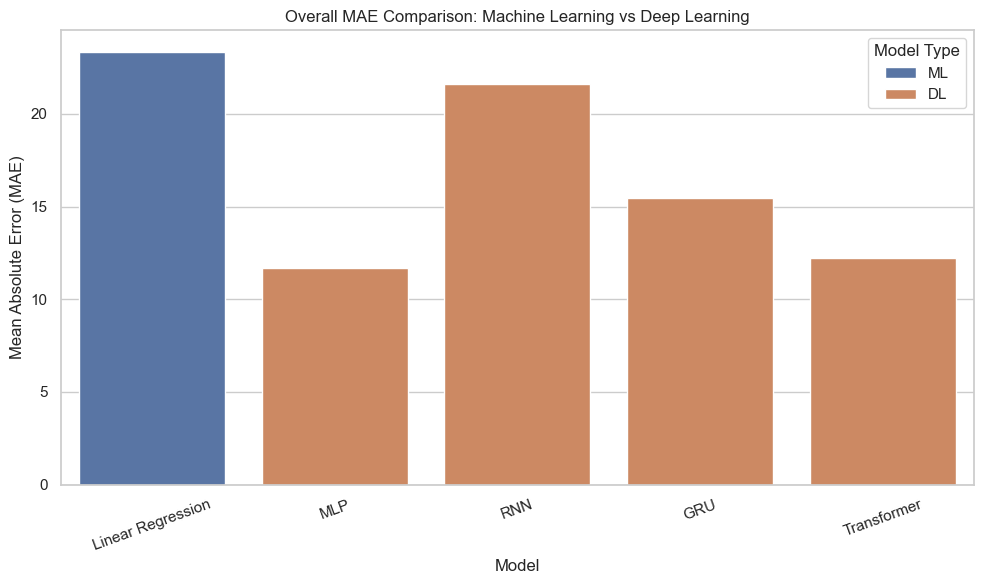

In [16]:
#  Overall MAE Comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=overall_regression_comparison,
    x="Model",
    y="MAE",
    hue="Model_Type",
    errorbar=None
)

plt.title("Overall MAE Comparison: Machine Learning vs Deep Learning")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error (MAE)")
plt.xticks(rotation=20)
plt.legend(title="Model Type")
plt.tight_layout()
plt.show()

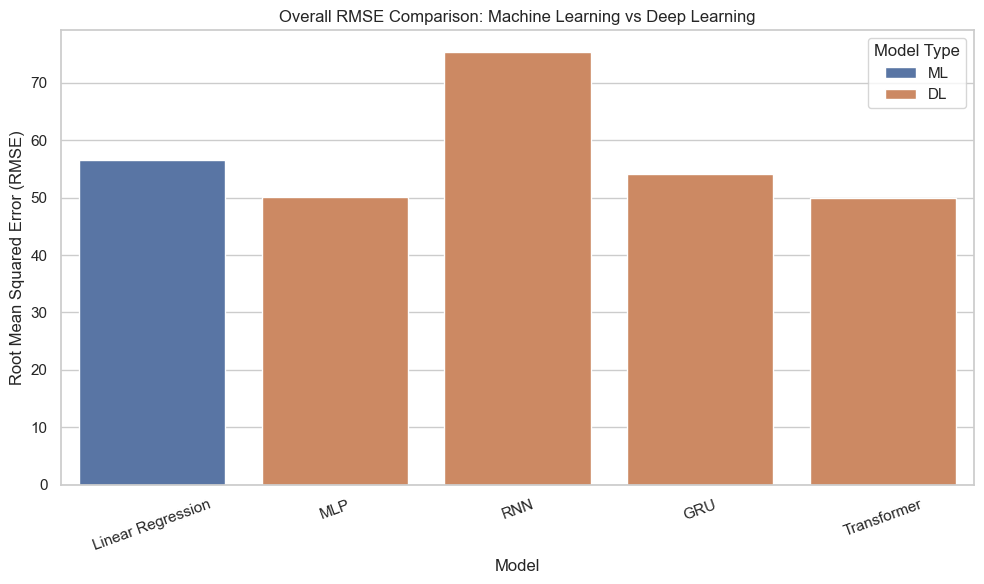

In [17]:
#  Overall RMSE Comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=overall_regression_comparison,
    x="Model",
    y="RMSE",
    hue="Model_Type",
    errorbar=None
)

plt.title("Overall RMSE Comparison: Machine Learning vs Deep Learning")
plt.xlabel("Model")
plt.ylabel("Root Mean Squared Error (RMSE)")
plt.xticks(rotation=20)
plt.legend(title="Model Type")
plt.tight_layout()
plt.show()

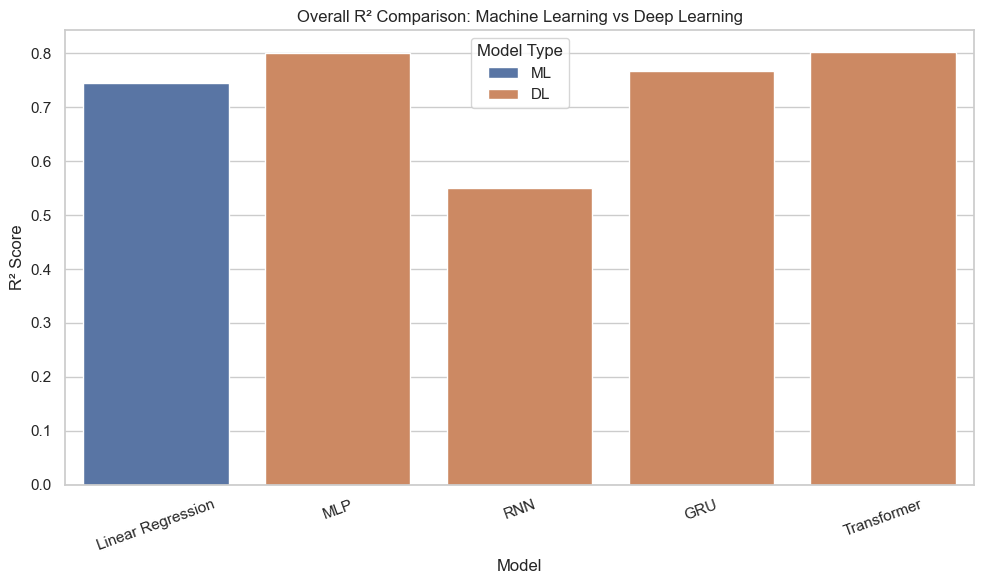

In [18]:
#  Overall R² Comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=overall_regression_comparison,
    x="Model",
    y="R2",
    hue="Model_Type",
    errorbar=None
)

plt.title("Overall R² Comparison: Machine Learning vs Deep Learning")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.xticks(rotation=20)
plt.legend(title="Model Type")
plt.tight_layout()
plt.show()

In [19]:
#  Extreme Pollution Regression Performance

extreme_columns = [
    "Model",
    "Model_Type",
    "Extreme_MAE",
    "Extreme_RMSE",
    "Extreme_R2"
]

extreme_regression_comparison = (
    regression_comparison_df[extreme_columns]
    .copy()
)

print("Extreme Pollution Regression Performance")
print("Threshold: US_AQI >= 201")

display(extreme_regression_comparison)

Extreme Pollution Regression Performance
Threshold: US_AQI >= 201


,Model,Model_Type,Extreme_MAE,Extreme_RMSE,Extreme_R2
0,Linear Regression,ML,201.9742,313.5034,0.4916
1,MLP,DL,208.2278,307.9689,0.5115
2,RNN,DL,297.3423,436.7031,0.0178
3,GRU,DL,194.6090,319.3998,0.4746
4,Transformer,DL,196.4280,303.3882,0.5260


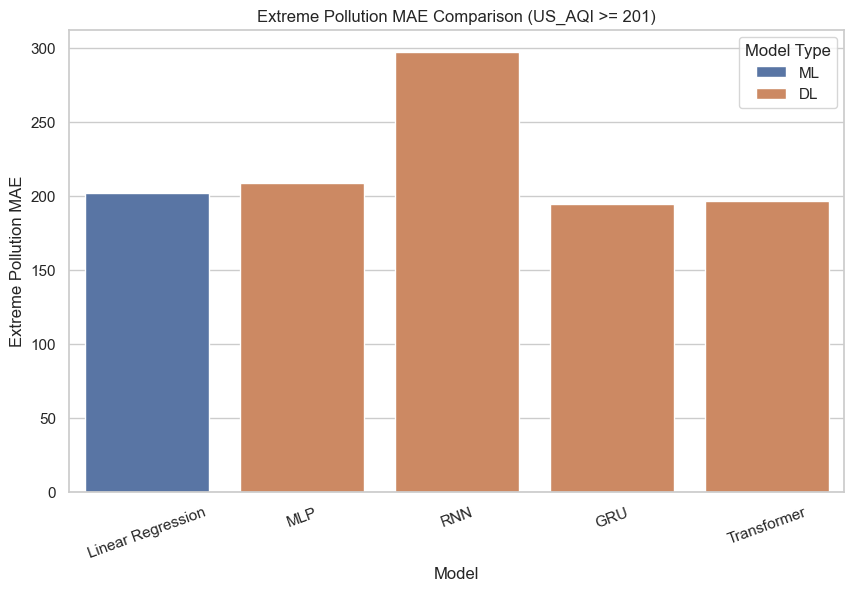

In [20]:
#  Extreme Pollution MAE Comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=extreme_regression_comparison,
    x="Model",
    y="Extreme_MAE",
    hue="Model_Type",
    errorbar=None
)

plt.title("Extreme Pollution MAE Comparison (US_AQI >= 201)")
plt.xlabel("Model")
plt.ylabel("Extreme Pollution MAE")
plt.xticks(rotation=20)
plt.legend(title="Model Type")

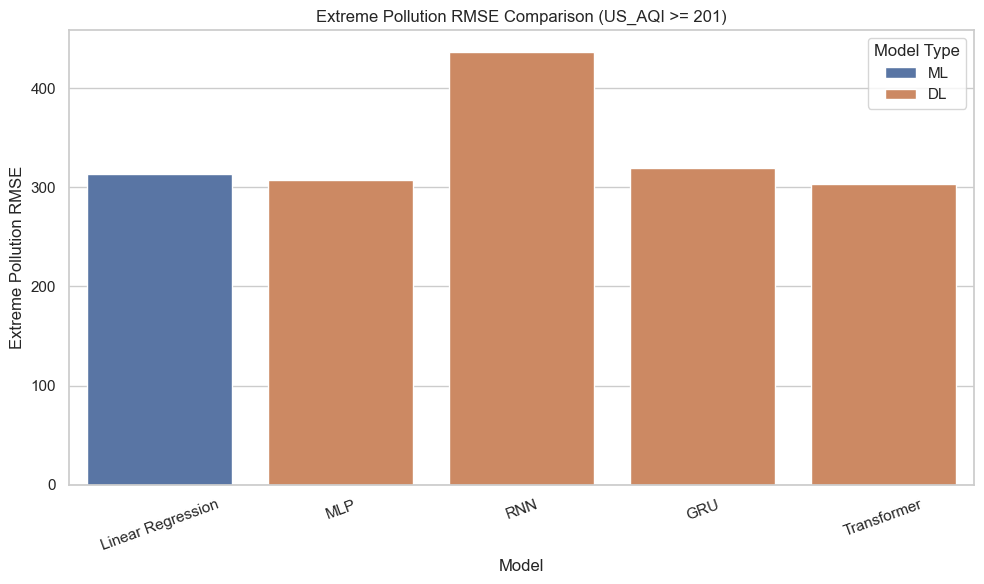

In [21]:
#  Extreme Pollution RMSE Comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=extreme_regression_comparison,
    x="Model",
    y="Extreme_RMSE",
    hue="Model_Type",
    errorbar=None
)

plt.title("Extreme Pollution RMSE Comparison (US_AQI >= 201)")
plt.xlabel("Model")
plt.ylabel("Extreme Pollution RMSE")
plt.xticks(rotation=20)
plt.legend(title="Model Type")
plt.tight_layout()
plt.show()

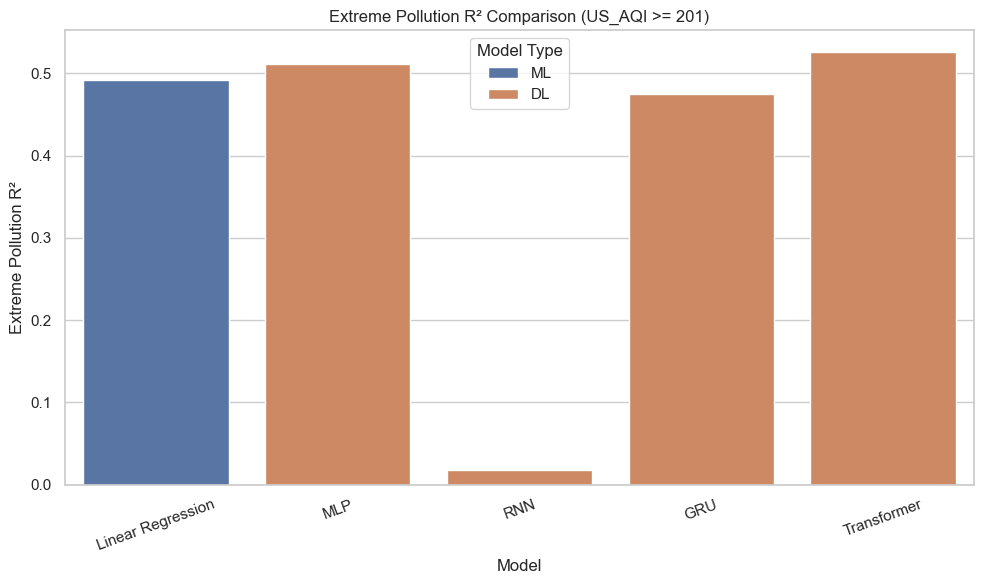

In [22]:
#  Extreme Pollution R² Comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=extreme_regression_comparison,
    x="Model",
    y="Extreme_R2",
    hue="Model_Type",
    errorbar=None
)

plt.title("Extreme Pollution R² Comparison (US_AQI >= 201)")
plt.xlabel("Model")
plt.ylabel("Extreme Pollution R²")
plt.xticks(rotation=20)
plt.legend(title="Model Type")
plt.tight_layout()
plt.show()

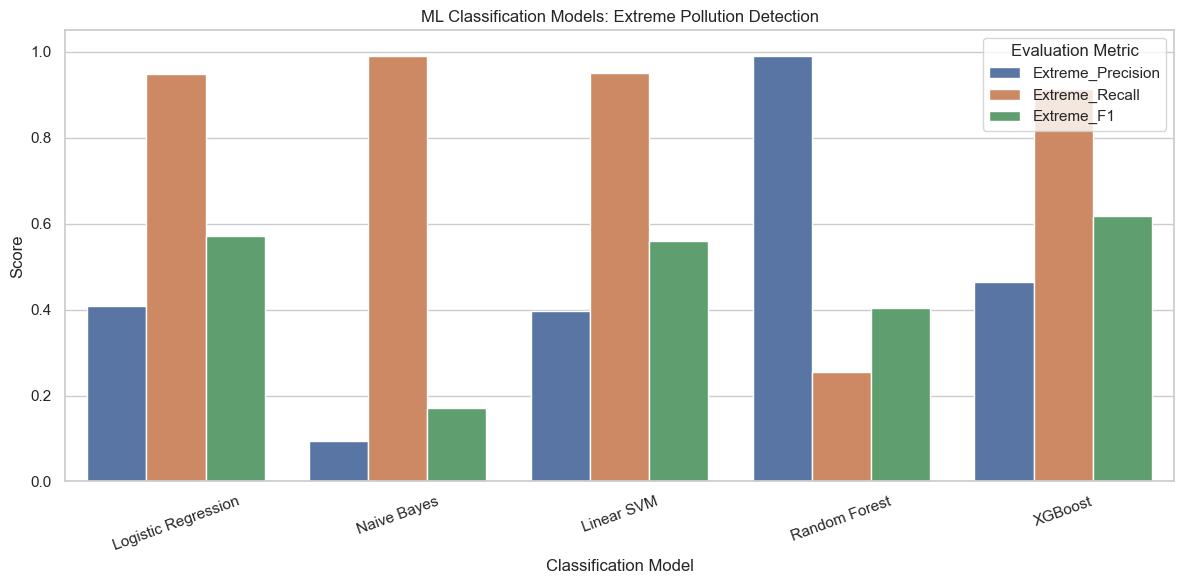

In [23]:
#  Classification Model Evaluation

classification_plot_df = ml_classification_results.melt(
    id_vars="Model",
    value_vars=[
        "Extreme_Precision",
        "Extreme_Recall",
        "Extreme_F1"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=classification_plot_df,
    x="Model",
    y="Score",
    hue="Metric",
    errorbar=None
)

plt.title("ML Classification Models: Extreme Pollution Detection")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0, 1.05)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

In [24]:
#  Model Performance Ranking

# Regression models: rank separately using MAE, RMSE and R²
regression_ranking = regression_comparison_df[
    ["Model", "Model_Type", "MAE", "RMSE", "R2"]
].copy()

regression_ranking["MAE_Rank"] = regression_ranking["MAE"].rank(
    ascending=True, method="min"
)
regression_ranking["RMSE_Rank"] = regression_ranking["RMSE"].rank(
    ascending=True, method="min"
)
regression_ranking["R2_Rank"] = regression_ranking["R2"].rank(
    ascending=False, method="min"
)

print("Regression Model Ranking")
display(regression_ranking.sort_values("RMSE_Rank"))


# Classification models: rank using Extreme Pollution F1-score
classification_ranking = ml_classification_results[
    ["Model", "Extreme_Precision", "Extreme_Recall", "Extreme_F1"]
].copy()

classification_ranking["F1_Rank"] = classification_ranking[
    "Extreme_F1"
].rank(ascending=False, method="min")

print("Classification Model Ranking (Extreme Pollution Detection)")
display(classification_ranking.sort_values("F1_Rank"))

Regression Model Ranking


,Model,Model_Type,MAE,RMSE,R2,MAE_Rank,RMSE_Rank,R2_Rank
4,Transformer,DL,12.2016,49.9385,0.8028,2.0,1.0,1.0
1,MLP,DL,11.6993,50.1122,0.8014,1.0,2.0,2.0
3,GRU,DL,15.4666,54.1908,0.7678,3.0,3.0,3.0
0,Linear Regression,ML,23.3420,56.5912,0.7460,5.0,4.0,4.0
2,RNN,DL,21.6034,75.3754,0.5507,4.0,5.0,5.0


Classification Model Ranking (Extreme Pollution Detection)


,Model,Extreme_Precision,Extreme_Recall,Extreme_F1,F1_Rank
4,XGBoost,0.4652,0.9146,0.6167,1.0
0,Logistic Regression,0.4091,0.9482,0.5716,2.0
2,Linear SVM,0.3963,0.9502,0.5593,3.0
3,Random Forest,0.9892,0.2543,0.4046,4.0
1,Naive Bayes,0.0935,0.9910,0.1710,5.0


Robustness Analysis: Overall vs Extreme Pollution


,Model,Model_Type,MAE,RMSE,Extreme_MAE,Extreme_RMSE,MAE_Degradation_%,RMSE_Degradation_%
0,Linear Regression,ML,23.34,56.59,201.97,313.50,765.28,453.98
3,GRU,DL,15.47,54.19,194.61,319.40,1158.25,489.40
2,RNN,DL,21.60,75.38,297.34,436.70,1276.37,479.37
4,Transformer,DL,12.20,49.94,196.43,303.39,1509.85,507.52
1,MLP,DL,11.70,50.11,208.23,307.97,1679.83,514.56


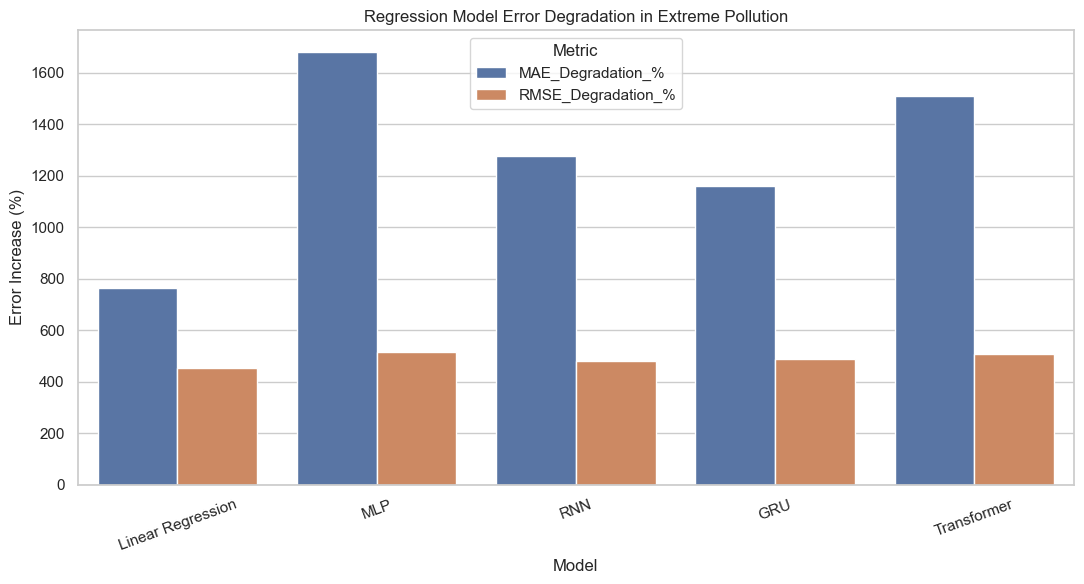

In [25]:
#  Robustness & Performance Degradation Analysis

robustness_df = regression_comparison_df[
    ["Model", "Model_Type", "MAE", "RMSE",
     "Extreme_MAE", "Extreme_RMSE"]
].copy()

robustness_df["MAE_Degradation_%"] = (
    (robustness_df["Extreme_MAE"] - robustness_df["MAE"])
    / robustness_df["MAE"]
) * 100

robustness_df["RMSE_Degradation_%"] = (
    (robustness_df["Extreme_RMSE"] - robustness_df["RMSE"])
    / robustness_df["RMSE"]
) * 100

print("Robustness Analysis: Overall vs Extreme Pollution")
display(
    robustness_df.sort_values(
        "MAE_Degradation_%",
        ascending=True
    ).round(2)
)

plt.figure(figsize=(11, 6))

robustness_plot_df = robustness_df.melt(
    id_vars=["Model", "Model_Type"],
    value_vars=["MAE_Degradation_%", "RMSE_Degradation_%"],
    var_name="Metric",
    value_name="Degradation_Percentage"
)

sns.barplot(
    data=robustness_plot_df,
    x="Model",
    y="Degradation_Percentage",
    hue="Metric",
    errorbar=None
)

plt.title("Regression Model Error Degradation in Extreme Pollution")
plt.xlabel("Model")
plt.ylabel("Error Increase (%)")
plt.xticks(rotation=20)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

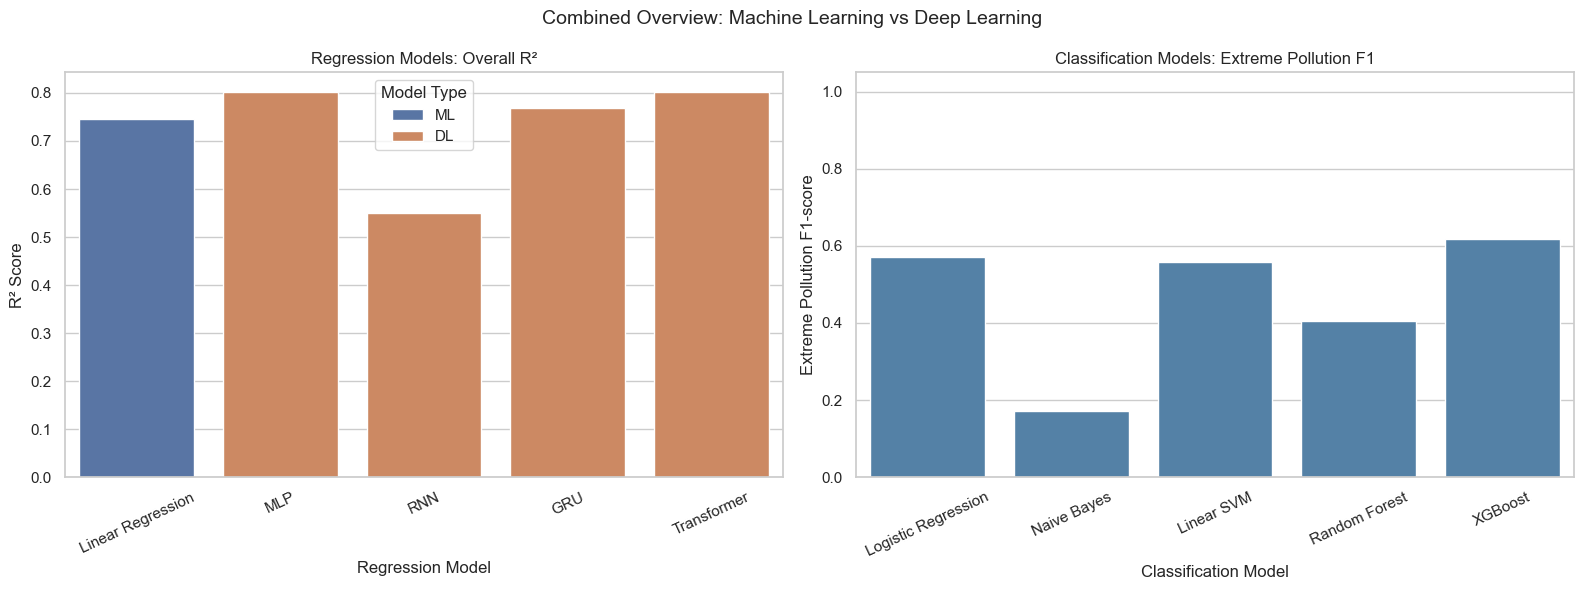

In [26]:
#  Combined ML vs DL Visualization

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Regression models
sns.barplot(
    data=regression_comparison_df,
    x="Model",
    y="R2",
    hue="Model_Type",
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title("Regression Models: Overall R²")
axes[0].set_xlabel("Regression Model")
axes[0].set_ylabel("R² Score")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(title="Model Type")

# Panel 2: Classification models
sns.barplot(
    data=ml_classification_results,
    x="Model",
    y="Extreme_F1",
    color="steelblue",
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title("Classification Models: Extreme Pollution F1")
axes[1].set_xlabel("Classification Model")
axes[1].set_ylabel("Extreme Pollution F1-score")
axes[1].tick_params(axis="x", rotation=25)
axes[1].set_ylim(0, 1.05)

fig.suptitle(
    "Combined Overview: Machine Learning vs Deep Learning",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [27]:
#  Best-Performing Model Summary

# Overall regression: lowest MAE and RMSE, highest R²
best_overall_mae = regression_comparison_df.loc[
    regression_comparison_df["MAE"].idxmin()
]

best_overall_rmse = regression_comparison_df.loc[
    regression_comparison_df["RMSE"].idxmin()
]

best_overall_r2 = regression_comparison_df.loc[
    regression_comparison_df["R2"].idxmax()
]

# Extreme pollution regression
best_extreme_mae = regression_comparison_df.loc[
    regression_comparison_df["Extreme_MAE"].idxmin()
]

best_extreme_rmse = regression_comparison_df.loc[
    regression_comparison_df["Extreme_RMSE"].idxmin()
]

best_extreme_r2 = regression_comparison_df.loc[
    regression_comparison_df["Extreme_R2"].idxmax()
]

# Classification: highest Extreme F1-score
best_classifier = ml_classification_results.loc[
    ml_classification_results["Extreme_F1"].idxmax()
]

print("BEST-PERFORMING MODEL SUMMARY")

print("\nOverall Regression:")
print("Lowest MAE:", best_overall_mae["Model"],
      "-", round(best_overall_mae["MAE"], 4))
print("Lowest RMSE:", best_overall_rmse["Model"],
      "-", round(best_overall_rmse["RMSE"], 4))
print("Highest R²:", best_overall_r2["Model"],
      "-", round(best_overall_r2["R2"], 4))

print("\nExtreme Pollution Regression (US_AQI >= 201):")
print("Lowest MAE:", best_extreme_mae["Model"],
      "-", round(best_extreme_mae["Extreme_MAE"], 4))
print("Lowest RMSE:", best_extreme_rmse["Model"],
      "-", round(best_extreme_rmse["Extreme_RMSE"], 4))
print("Highest R²:", best_extreme_r2["Model"],
      "-", round(best_extreme_r2["Extreme_R2"], 4))

print("\nExtreme Pollution Classification:")
print("Highest F1-score:", best_classifier["Model"],
      "-", round(best_classifier["Extreme_F1"], 4))

BEST-PERFORMING MODEL SUMMARY

Overall Regression:
Lowest MAE: MLP - 11.6993
Lowest RMSE: Transformer - 49.9385
Highest R²: Transformer - 0.8028

Extreme Pollution Regression (US_AQI >= 201):
Lowest MAE: GRU - 194.609
Lowest RMSE: Transformer - 303.3882
Highest R²: Transformer - 0.526

Extreme Pollution Classification:
Highest F1-score: XGBoost - 0.6167


##  Key Research Findings and Limitations

### Key Research Findings

1. **Overall Regression Performance:** The recorded regression results show differences in MAE, RMSE, and R² across the Linear Regression, MLP, RNN, GRU, and Transformer models.

2. **Deep Learning Performance:** Among the recorded regression results, the Transformer achieved the lowest overall RMSE (49.9385), while the MLP achieved the lowest overall MAE (11.6993). The Transformer also recorded the highest overall R² (0.8028).

3. **Extreme Pollution Performance:** For observations with US_AQI ≥ 201, the Transformer recorded the lowest RMSE (303.3882) and highest R² (0.5260). The GRU recorded the lowest MAE (194.6090).

4. **Extreme Pollution Classification:** Among the recorded classification results, XGBoost achieved the highest extreme-pollution F1-score (0.6167). Random Forest achieved high precision (0.9892), but its recall was comparatively low (0.2543), indicating that it missed many extreme-pollution cases.

5. **Performance Under Extreme Conditions:** The recorded regression errors were generally higher for the extreme-pollution subset than for the overall dataset. This indicates that predicting AQI during extreme pollution episodes remains challenging.

### Research Limitations

- The regression and classification models perform different prediction tasks; their metrics should not be directly compared or combined into a single performance ranking.
- The extreme-pollution threshold used in this analysis is US_AQI ≥ 201.
- Extreme-pollution observations may have a different sample size and target distribution from the overall dataset.
- The recorded metrics must be verified against the original model evaluation outputs before final publication.
- The evaluation alone does not establish that the models generalize to unseen locations, future pollution episodes, or other datasets.
- Data leakage, preprocessing consistency, train-test separation, and temporal validation must be checked in the original training notebooks before drawing definitive conclusions.

### Interpretation

The results suggest that model performance depends on both the evaluation metric and the pollution conditions. A model that performs well on the overall dataset may not be the best choice for extreme pollution detection. Therefore, model selection should consider prediction error, extreme-event performance, and the consequences of missing severe pollution episodes.

##  Final Research Conclusion

### Conclusion

This study compares six machine learning models and four deep learning models for air quality prediction and examines their performance under extreme pollution conditions.

The regression analysis evaluates Linear Regression, MLP, RNN, GRU, and Transformer using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R². The classification analysis evaluates Logistic Regression, Naive Bayes, Linear SVM, Random Forest, and XGBoost using classification metrics, with particular attention to extreme-pollution precision, recall, and F1-score.

The recorded results indicate that model performance varies according to the evaluation metric and pollution conditions. The Transformer achieved the lowest overall RMSE among the recorded regression results, while the MLP achieved the lowest overall MAE. For extreme-pollution regression, the Transformer recorded the lowest RMSE, whereas the GRU recorded the lowest MAE. In classification, XGBoost achieved the highest recorded F1-score for extreme-pollution detection.

These findings suggest that evaluating models only on overall performance may not be sufficient for applications involving severe pollution episodes. Extreme-event detection and prediction errors should also be considered when selecting a model for practical use.

However, these conclusions are preliminary and depend on the validity and comparability of the recorded evaluation results. Before finalizing the research, the original model outputs, preprocessing procedures, data splits, and leakage checks should be verified. Further evaluation on independent data and future pollution episodes would help establish the models' generalization and practical reliability.

Overall, this comparison provides a structured basis for investigating how machine learning and deep learning models perform under normal and extreme air pollution conditions.